# Kinase Drug Discovery — Notebook 1
## Introduction: kinase biology, inhibitor chemistry and binding-site structure

**Learning goals**

After this notebook you should be able to

1. explain what protein kinases do and why they are attractive (and difficult) drug targets;
2. name the structural landmarks of the kinase domain (hinge, gatekeeper, P-loop, αC-helix, DFG motif, activation loop) and the KLIFS pocket definition;
3. classify kinase inhibitors by binding mode (type I, I½, II, III, IV, covalent);
4. use RDKit to compare the physicochemical properties and chemotypes of approved kinase inhibitors;
5. use Biopython to locate kinase landmarks in a crystal structure and classify the **DFG** and **αC-helix** conformations.

**Runtime:** ~5 minutes on 4 CPU cores (most of it downloading 4 small PDB files). No GPU needed.

**Series overview**

| Notebook | Topic |
|---|---|
| **1 (this one)** | Domain knowledge, inhibitor chemistry, kinase structure |
| 2 | Ligand-based modelling: QSAR and proteochemometrics (PCM) on ChEMBL kinase data |
| 3 | Structure-based modelling: docking with AutoDock Vina and molecular dynamics with OpenMM |

## 0. Setup

Run the cell below first. It limits every numerical library to 4 threads (the target hardware), creates a `data/` folder and checks that the required packages are importable. If something is missing, run `install_apt.sh` (Ubuntu 24.04) or `python3 check_env.py` to see what to install (see `README.md`).

In [1]:
import os
N_CPU = min(4, os.cpu_count() or 1)
for _v in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"]:
    os.environ.setdefault(_v, str(N_CPU))

import importlib, sys, time
from pathlib import Path

DATA = Path("data")
DATA.mkdir(exist_ok=True)

for pkg in ["numpy", "pandas", "matplotlib", "seaborn", "rdkit", "Bio", "requests"]:
    try:
        m = importlib.import_module(pkg)
        print(f"{pkg:12s} {getattr(m, '__version__', 'ok')}")
    except ImportError:
        print(f"{pkg:12s} MISSING  -> see README.md (install_apt.sh)")
try:
    import py3Dmol
    print("py3Dmol      ", py3Dmol.__version__ if hasattr(py3Dmol, "__version__") else "ok")
except ImportError:
    import mini3dmol as py3Dmol      # bundled stand-in (py3Dmol is not packaged for Ubuntu)
    print("py3Dmol       not installed -> using bundled mini3dmol.py for 3D views")
print("Python", sys.version.split()[0], "| using", N_CPU, "threads")

numpy        1.26.4
pandas       2.3.3
matplotlib   3.11.1
seaborn      0.13.2
rdkit        2026.03.3
Bio          1.87
requests     2.33.1
py3Dmol       2.5.5
Python 3.13.13 | using 4 threads


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests

from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, Crippen, Lipinski, rdMolDescriptors, QED, Draw, rdFingerprintGenerator

pd.set_option("display.width", 160)
sns.set_theme(context="notebook", style="whitegrid")


def download(url, dest, retries=3):
    """Download `url` to `dest` once; later calls reuse the cached file."""
    dest = Path(dest)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    for attempt in range(1, retries + 1):
        try:
            r = requests.get(url, timeout=60)
            r.raise_for_status()
            dest.write_bytes(r.content)
            return dest
        except Exception as exc:  # network hiccup -> retry
            print(f"  attempt {attempt} failed for {url}: {exc}")
            time.sleep(2 * attempt)
    raise RuntimeError(f"Could not download {url}. Check your internet connection.")

## 1. Protein kinases in a nutshell

Protein kinases transfer the γ-phosphate of **ATP** to the hydroxyl group of a **serine, threonine or tyrosine** residue in a substrate protein. Phosphorylation switches protein activity, localisation and interactions on or off, making kinases the central relay stations of cellular signalling (growth, division, differentiation, immune response, metabolism).

* The human genome encodes ~**520 protein kinases** — the *kinome* (Manning *et al.*, Science 2002). They are grouped into families by sequence: **AGC, CAMK, CK1, CMGC, STE, TK** (tyrosine kinases), **TKL** (tyrosine-kinase-like), plus "atypical" kinases.
* Deregulated kinase activity (mutation, amplification, translocation) drives many cancers. The textbook case is the **BCR-ABL** fusion in chronic myeloid leukaemia (CML), a constitutively active tyrosine kinase.
* **Imatinib** (Gleevec, approved 2001) showed that a selective kinase inhibitor can turn a lethal leukaemia into a manageable chronic disease. Since then more than 80 small-molecule kinase inhibitors have been approved by the FDA, most for oncology but increasingly for inflammation and autoimmunity (e.g. JAK inhibitors).

### Why are kinases attractive — and hard — drug targets?

| Pro | Con |
|---|---|
| Deep, well-defined ATP pocket ("druggable") | ATP pocket is **conserved** across ~500 kinases → selectivity is difficult |
| Strong genetic validation in oncology | Cellular ATP concentration is high (mM) → inhibitors need high affinity |
| Large structural & bioactivity datasets (PDB, KLIFS, ChEMBL, Papyrus) | **Resistance mutations** emerge quickly (e.g. gatekeeper T315I in ABL, T790M in EGFR) |
| Many binding modes beyond the ATP site (allosteric, covalent) | Off-target toxicity (cardiotoxicity, etc.) |

## 2. Anatomy of the kinase domain

All eukaryotic protein kinases share a ~250-residue catalytic domain with two lobes:

* **N-lobe** — a five-stranded β-sheet plus one helix, the **αC-helix**.
  * **Glycine-rich loop / P-loop** (motif G-x-G-x-x-G) covers the phosphates of ATP.
  * **β3-Lys** (e.g. K271 in ABL) binds the α/β-phosphates and forms a **salt bridge with the αC-Glu** (E286 in ABL) when the kinase is active (**αC-in**). Moving the helix outward breaks this salt bridge (**αC-out**).
* **C-lobe** — mostly α-helical; contains the **catalytic loop (HRD motif)** and the **activation loop**, which starts with the **DFG motif** (Asp-Phe-Gly).
  * **DFG-in**: Asp points into the ATP site to coordinate Mg²⁺ — catalytically competent.
  * **DFG-out**: the Asp and Phe swap positions ("flip"), which opens an extra hydrophobic **back pocket** next to the ATP site.
* **Hinge** — the linker between the lobes. Its backbone NH/C=O groups make the **hydrogen bonds with the adenine of ATP**; almost every ATP-competitive inhibitor copies these H-bonds (e.g. Met318 in ABL, Met793 in EGFR).
* **Gatekeeper** — the residue just before the hinge, controlling access to the back pocket. A small gatekeeper (Thr, Val) allows bulky inhibitors in; mutation to a larger residue (T315I in ABL, T790M in EGFR) is a classic resistance mechanism.

### The KLIFS pocket definition

To compare binding sites across kinases, **KLIFS** (van Linden *et al.*, J Med Chem 2014; Kanev *et al.*, NAR 2021) defines **85 structurally aligned pocket residues**, grouped into regions:

| Positions | Region | Positions | Region |
|---|---|---|---|
| 1–3 | β1 (I) | 46–48 | **hinge** |
| 4–9 | **glycine-rich loop (g.l)** | 49–52 | linker |
| 10–13 | β2 (II) | 53–59 | αD |
| 14–19 | β3 (III), **K17 = catalytic Lys** | 60–64 | αE |
| 20–30 | **αC**, **E24 = conserved Glu** | 65–67 | β6 (VI) |
| 31–37 | back loop (b.l) | 68–75 | catalytic loop (c.l) |
| 38–41 | β4 (IV) | 76–78 | β7 (VII) |
| 42–44 | β5 (V) | 79 | β8 (VIII) |
| **45** | **gatekeeper (GK)** | 80–83 | **xDFG** (81–83 = D-F-G) |
| | | 84–85 | activation loop (a.l) |

Because every kinase gets the same 85 positions, the KLIFS pocket is a ready-made **multiple sequence alignment of binding sites** — we will use it in Notebook 2 as the protein descriptor for proteochemometrics.

In [4]:
# KLIFS pocket sequences (85 aligned residues, '-' = gap), retrieved from the KLIFS API (klifs.net).
KLIFS_POCKETS = {
    "EGFR":  "KVLGSGAFGTVYKVAIKELEILDEAYVMASVDPHVCRLLGIQLITQLMPFGCLLDYVREYLEDRRLVHRDLAARNVLVITDFGLA",
    "ERBB2": "KVLGSGAFGTVYKVAIKVLEILDEAYVMAGVGPYVSRLLGIQLVTQLMPYGCLLDHVREYLEDVRLVHRDLAARNVLVITDFGLA",
    "ABL1":  "HKLGGGQYGEVYEVAVKTLEFLKEAAVMKEIKPNLVQLLGVYIITEFMTYGNLLDYLREYLEKKNFIHRDLAARNCLVVADFGLS",
    "SRC":   "VKLGQGCFGEVWMVAIKTLAFLQEAQVMKKLREKLVQLYAVYIVTEYMSKGSLLDFLKGYVERMNYVHRDLRAANILVVADFGLA",
    "LCK":   "ERLGAGQFGEVWMVAVKSLAFLAEANLMKQLQQRLVRLYAVYIITEYMENGSLVDFLKTFIEERNYIHRDLRAANILVIADFGLA",
    "BTK":   "KELGTGQFGVVKYVAIKMIEFIEEAKVMMNLSEKLVQLYGVFIITEYMANGCLLNYLREYLESKQFLHRDLAARNCLVVSDFGLS",
    "KIT":   "KTLGAGAFGKVVEVAVKMLALMSELKVLSYLGMNIVNLLGALVITEYCCYGDLLNFLRRFLASKNCIHRDLAARNILLICDFGLA",
    "KDR":   "KPLGRGAFGQVIEVAVKMLALMSELKILIHIGLNVVNLLGAMVIVEFCKFGNLSTYLRSFLASRKCIHRDLAARNILLICDFGLA",
    "FLT3":  "KVLGSGAFGKVMNVAVKMLALMSELKMMTQLGENIVNLLGAYLIFEYCCYGDLLNYLRSFLEFKSCVHRDLAARNVLVICDFGLA",
    "JAK2":  "QQLGKGNFGSVEMVAVKKLDFEREIEILKSLQDNIVKYKGVKLIMEYLPYGSLRDYLQKYLGTKRYIHRDLATRNILVIGDFGLT",
    "AURKA": "RPLGKGKFGNVYLLALKVLQLRREVEIQSHLRPNILRLYGYYLILEYAPLGTVYRELQKYCHSKRVIHRDIKPENLLLIADFGWS",
    "CDK2":  "EKIGEGTYGVVYKVALKKITAIREISLLKELNPNIVKLLDVYLVFEFLH-QDLKKFMDAFCHSHRVLHRDLKPQNLLILADFGLA",
}

KLIFS_REGIONS = [("I", 1, 3), ("g.l", 4, 9), ("II", 10, 13), ("III", 14, 19), ("αC", 20, 30),
                 ("b.l", 31, 37), ("IV", 38, 41), ("V", 42, 44), ("GK", 45, 45), ("hinge", 46, 48),
                 ("linker", 49, 52), ("αD", 53, 59), ("αE", 60, 64), ("VI", 65, 67), ("c.l", 68, 75),
                 ("VII", 76, 78), ("VIII", 79, 79), ("xDFG", 80, 83), ("a.l", 84, 85)]

def klifs_region(pos):
    for name, start, end in KLIFS_REGIONS:
        if start <= pos <= end:
            return name

# Sanity check: conserved landmarks sit at the same KLIFS position in every kinase
landmarks = pd.DataFrame({k: {"g.l (4-9)": p[3:9], "K17": p[16], "E24": p[23], "GK45": p[44],
                              "hinge 46-48": p[45:48], "c.l (68-75)": p[67:75], "DFG 81-83": p[80:83]}
                          for k, p in KLIFS_POCKETS.items()}).T
landmarks

,g.l (4-9),K17,E24,GK45,hinge 46-48,c.l (68-75),DFG 81-83
EGFR,GSGAFG,K,E,T,QLM,HRDLAARN,DFG
ERBB2,GSGAFG,K,E,T,QLM,HRDLAARN,DFG
ABL1,GGGQYG,K,E,T,EFM,HRDLAARN,DFG
SRC,GQGCFG,K,E,T,EYM,HRDLRAAN,DFG
LCK,GAGQFG,K,E,T,EYM,HRDLRAAN,DFG
BTK,GTGQFG,K,E,T,EYM,HRDLAARN,DFG
KIT,GAGAFG,K,E,T,EYC,HRDLAARN,DFG
KDR,GRGAFG,K,E,V,EFC,HRDLAARN,DFG
FLT3,GSGAFG,K,E,F,EYC,HRDLAARN,DFG
JAK2,GKGNFG,K,E,M,EYL,HRDLATRN,DFG


Note how **K17, E24 and DFG** are identical in all 12 kinases (they are needed for catalysis) and the glycine-rich loop always has its G-x-G-x-x-G pattern, whereas the **gatekeeper (GK45)** varies: Thr in EGFR/ABL1/SRC, Val in KDR, Phe in FLT3/CDK2, Met in JAK2, Leu in AURKA.

**Exercise 1.1** — Compute the pairwise pocket sequence identity between the 12 kinases (ignore positions where either sequence has a gap) and show it as a clustered heat map. Which kinases have the most similar pockets? Would you expect a SRC inhibitor to also hit ABL1?

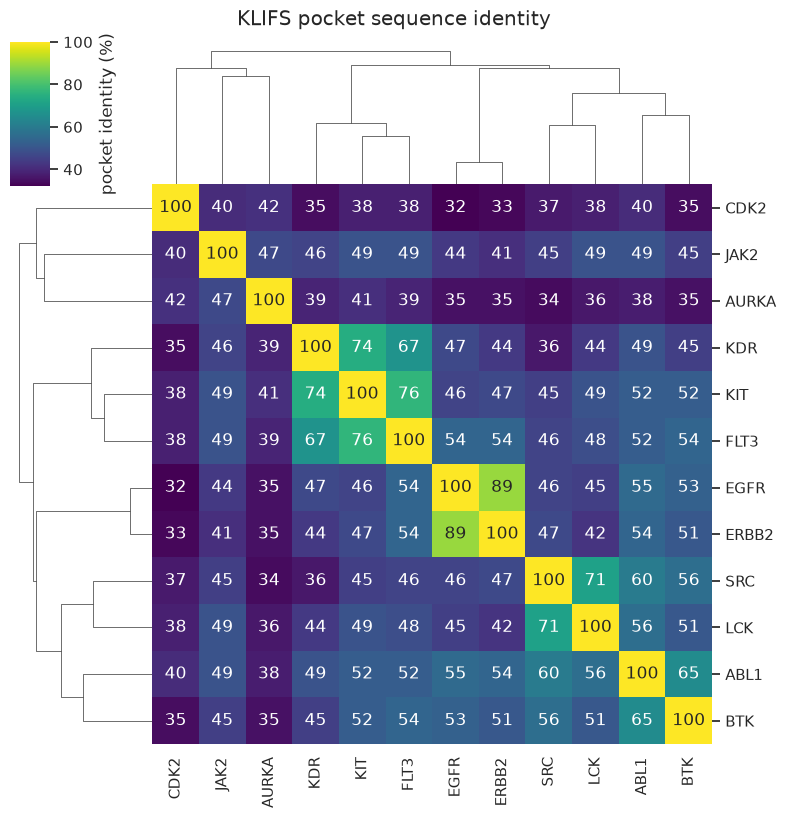

In [5]:
def pocket_identity(a, b):
    pairs = [(x, y) for x, y in zip(a, b) if x != "-" and y != "-"]
    return 100.0 * sum(x == y for x, y in pairs) / len(pairs)

names = list(KLIFS_POCKETS)
ident = pd.DataFrame([[pocket_identity(KLIFS_POCKETS[a], KLIFS_POCKETS[b]) for b in names] for a in names],
                     index=names, columns=names)
g = sns.clustermap(ident, cmap="viridis", annot=True, fmt=".0f", figsize=(8, 8),
                   cbar_kws={"label": "pocket identity (%)"})
g.fig.suptitle("KLIFS pocket sequence identity", y=1.02)
plt.show()

<details><summary><b>Discussion</b> (click to expand)</summary>

The tyrosine kinases cluster together; EGFR/ERBB2, the SRC-family pair SRC/LCK, and the PDGFR-family kinases KIT/KDR/FLT3 have the most similar pockets. ABL1 and SRC share a large fraction of their pocket residues (including the Thr gatekeeper), and indeed **dasatinib** and **bosutinib** are dual SRC/ABL inhibitors. The serine/threonine kinases AURKA and CDK2 are clearly separated. High pocket identity is a useful—but not perfect—predictor of cross-reactivity: conformational preferences (e.g. ability to adopt DFG-out) matter as well.
</details>

## 3. How do kinase inhibitors bind? A classification

| Type | Binding site / conformation | Example |
|---|---|---|
| **I** | ATP site, active conformation (DFG-in, αC-in) | dasatinib, gefitinib, erlotinib, ruxolitinib |
| **I½** | ATP site + back pocket, DFG-in but αC-out | lapatinib, vemurafenib |
| **II** | ATP site + back pocket, **DFG-out** (inactive) | imatinib, nilotinib, ponatinib, sorafenib |
| **III** | Allosteric, adjacent to the ATP site (back pocket, not overlapping ATP) | trametinib (MEK1/2) |
| **IV** | Allosteric, remote from the ATP site | asciminib (ABL myristoyl pocket) |
| **VI (covalent)** | Reversible scaffold + electrophilic "warhead" reacting with a Cys | osimertinib (EGFR C797), ibrutinib (BTK C481), afatinib |

(After Dar & Shokat, Annu Rev Biochem 2011, and Roskoski, Pharmacol Res 2016. Type V — bivalent inhibitors — is omitted.)

Below is a small, hand-curated set of 20 approved kinase inhibitors. SMILES are neutral parent structures (no salts).

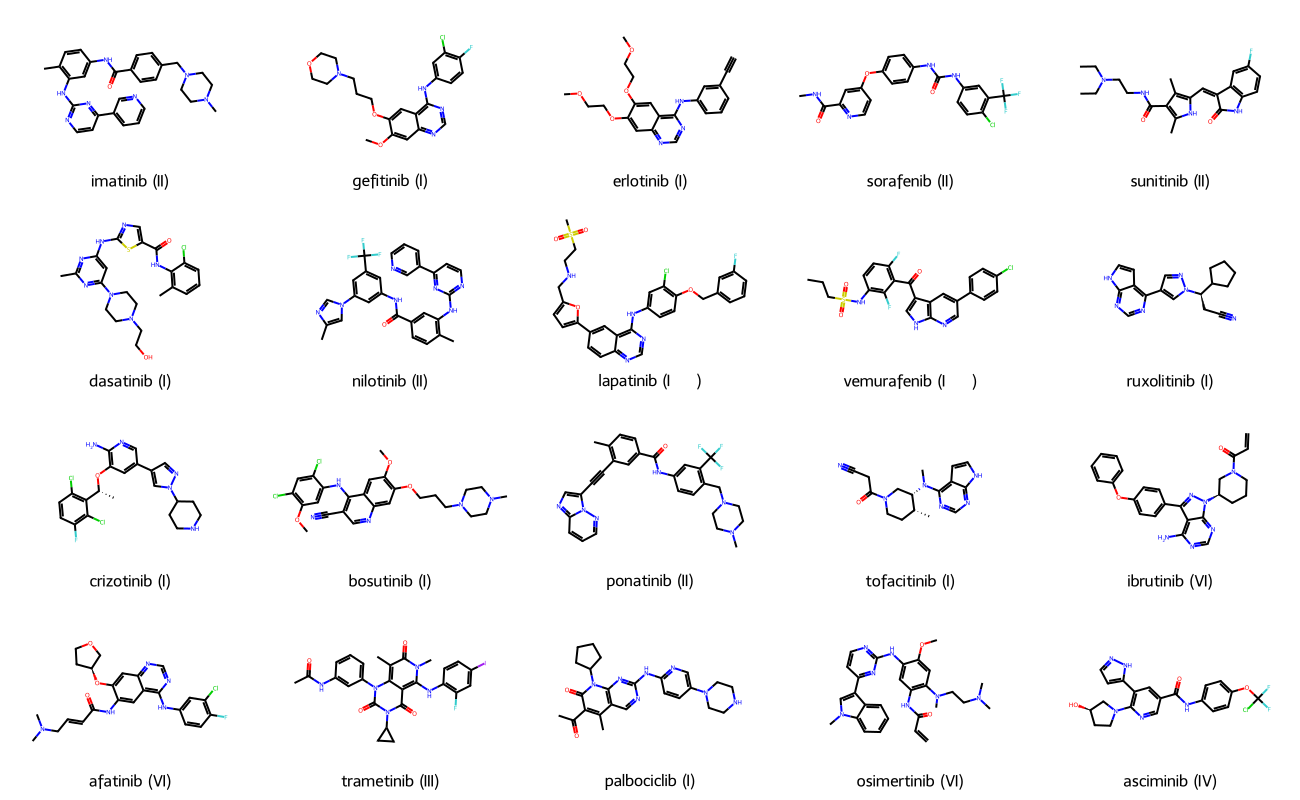

In [6]:
drugs = pd.DataFrame([
    # name,          SMILES,                                                                                      primary target(s),          type,  FDA year
    ("imatinib",    r"Cc1ccc(NC(=O)c2ccc(CN3CCN(C)CC3)cc2)cc1Nc1nccc(-c2cccnc2)n1",                              "BCR-ABL, KIT, PDGFR",      "II",  2001),
    ("gefitinib",   r"COc1cc2ncnc(Nc3ccc(F)c(Cl)c3)c2cc1OCCCN1CCOCC1",                                           "EGFR",                     "I",   2003),
    ("erlotinib",   r"COCCOc1cc2ncnc(Nc3cccc(C#C)c3)c2cc1OCCOC",                                                 "EGFR",                     "I",   2004),
    ("sorafenib",   r"CNC(=O)c1cc(Oc2ccc(NC(=O)Nc3ccc(Cl)c(C(F)(F)F)c3)cc2)ccn1",                                "RAF, VEGFR, PDGFR",        "II",  2005),
    ("sunitinib",   r"CCN(CC)CCNC(=O)c1c(C)[nH]c(/C=C2\C(=O)Nc3ccc(F)cc32)c1C",                                  "VEGFR, PDGFR, KIT",        "II",  2006),
    ("dasatinib",   r"Cc1nc(Nc2ncc(C(=O)Nc3c(C)cccc3Cl)s2)cc(N2CCN(CCO)CC2)n1",                                  "BCR-ABL, SRC family",      "I",   2006),
    ("nilotinib",   r"Cc1cn(-c2cc(NC(=O)c3ccc(C)c(Nc4nccc(-c5cccnc5)n4)c3)cc(C(F)(F)F)c2)cn1",                   "BCR-ABL",                  "II",  2007),
    ("lapatinib",   r"CS(=O)(=O)CCNCc1ccc(-c2ccc3ncnc(Nc4ccc(OCc5cccc(F)c5)c(Cl)c4)c3c2)o1",                    "EGFR, HER2",               "I½",  2007),
    ("vemurafenib", r"CCCS(=O)(=O)Nc1ccc(F)c(C(=O)c2c[nH]c3ncc(-c4ccc(Cl)cc4)cc23)c1F",                          "BRAF V600E",               "I½",  2011),
    ("ruxolitinib", r"N#CC[C@H](C1CCCC1)n1cc(-c2ncnc3[nH]ccc23)cn1",                                             "JAK1, JAK2",               "I",   2011),
    ("crizotinib",  r"C[C@@H](Oc1cc(-c2cnn(C3CCNCC3)c2)cnc1N)c1c(Cl)ccc(F)c1Cl",                                 "ALK, MET, ROS1",           "I",   2011),
    ("bosutinib",   r"COc1cc(Nc2c(C#N)cnc3cc(OCCCN4CCN(C)CC4)c(OC)cc23)c(Cl)cc1Cl",                              "BCR-ABL, SRC",             "I",   2012),
    ("ponatinib",   r"Cc1ccc(C(=O)Nc2ccc(CN3CCN(C)CC3)c(C(F)(F)F)c2)cc1C#Cc1cnc2cccnn12",                        "BCR-ABL incl. T315I",      "II",  2012),
    ("tofacitinib", r"C[C@@H]1CCN(C(=O)CC#N)C[C@@H]1N(C)c1ncnc2[nH]ccc12",                                       "JAK family",               "I",   2012),
    ("ibrutinib",   r"C=CC(=O)N1CCC[C@@H](n2nc(-c3ccc(Oc4ccccc4)cc3)c3c(N)ncnc32)C1",                            "BTK (C481)",               "VI",  2013),
    ("afatinib",    r"CN(C)C/C=C/C(=O)Nc1cc2c(Nc3ccc(F)c(Cl)c3)ncnc2cc1O[C@H]1CCOC1",                           "EGFR, HER2 (C797)",        "VI",  2013),
    ("trametinib",  r"CC(=O)Nc1cccc(-n2c(=O)n(C3CC3)c(=O)c3c(Nc4ccc(I)cc4F)n(C)c(=O)c(C)c32)c1",                "MEK1/2 (allosteric)",      "III", 2013),
    ("palbociclib", r"CC(=O)c1c(C)c2cnc(Nc3ccc(N4CCNCC4)cn3)nc2n(C2CCCC2)c1=O",                                  "CDK4/6",                   "I",   2015),
    ("osimertinib", r"C=CC(=O)Nc1cc(Nc2nccc(-c3cn(C)c4ccccc34)n2)c(OC)cc1N(C)CCN(C)C",                           "EGFR T790M (C797)",        "VI",  2015),
    ("asciminib",   r"O[C@@H]1CCN(c2ncc(C(=O)Nc3ccc(OC(F)(Cl)F)cc3)cc2-c2ccn[nH]2)C1",                           "BCR-ABL (myristoyl site)", "IV",  2021),
], columns=["name", "smiles", "target", "type", "year"])

drugs["mol"] = drugs.smiles.apply(Chem.MolFromSmiles)
assert drugs.mol.notna().all(), "a SMILES failed to parse"
Draw.MolsToGridImage(drugs.mol.tolist(), molsPerRow=5, subImgSize=(260, 200),
                     legends=[f"{n} ({t})" for n, t in zip(drugs.name, drugs.type)])

### 3.1 Physicochemical properties

Kinase inhibitors are often described as "flat, aromatic and lipophilic" — they mimic adenine and must reach an intracellular target. Let's quantify this with standard descriptors and Lipinski's Rule of Five (Ro5: MW ≤ 500, cLogP ≤ 5, HBD ≤ 5, HBA ≤ 10).

In [7]:
def properties(m):
    return pd.Series({
        "MW": Descriptors.MolWt(m),
        "cLogP": Crippen.MolLogP(m),
        "HBD": Lipinski.NumHDonors(m),
        "HBA": Lipinski.NumHAcceptors(m),
        "TPSA": rdMolDescriptors.CalcTPSA(m),
        "RotB": rdMolDescriptors.CalcNumRotatableBonds(m),
        "AroRings": rdMolDescriptors.CalcNumAromaticRings(m),
        "Fsp3": rdMolDescriptors.CalcFractionCSP3(m),
        "QED": QED.qed(m),
    })

props = pd.concat([drugs[["name", "type", "year"]], drugs.mol.apply(properties)], axis=1)
props["Ro5_violations"] = ((props.MW > 500).astype(int) + (props.cLogP > 5).astype(int)
                           + (props.HBD > 5).astype(int) + (props.HBA > 10).astype(int))
props.round(2).sort_values("year")

,name,type,year,MW,cLogP,HBD,HBA,TPSA,RotB,AroRings,Fsp3,QED,Ro5_violations
0,imatinib,II,2001,493.62,4.59,2.0,7.0,86.28,7.0,4.0,0.24,0.39,0
1,gefitinib,I,2003,446.91,4.28,1.0,7.0,68.74,8.0,3.0,0.36,0.52,0
2,erlotinib,I,2004,393.44,3.41,1.0,7.0,74.73,10.0,3.0,0.27,0.42,0
3,sorafenib,II,2005,464.83,5.55,3.0,4.0,92.35,5.0,3.0,0.10,0.46,1
4,sunitinib,II,2006,398.48,3.33,3.0,3.0,77.23,7.0,2.0,0.36,0.63,0
5,dasatinib,I,2006,488.02,3.31,3.0,9.0,106.51,7.0,3.0,0.36,0.47,0
6,nilotinib,II,2007,529.53,6.36,2.0,6.0,97.62,6.0,5.0,0.11,0.27,2
7,lapatinib,I½,2007,581.07,6.14,2.0,8.0,106.35,11.0,5.0,0.17,0.18,2
8,vemurafenib,I½,2011,489.93,5.54,2.0,4.0,91.92,7.0,4.0,0.13,0.33,1
9,ruxolitinib,I,2011,306.37,3.47,1.0,4.0,83.18,4.0,3.0,0.41,0.80,0


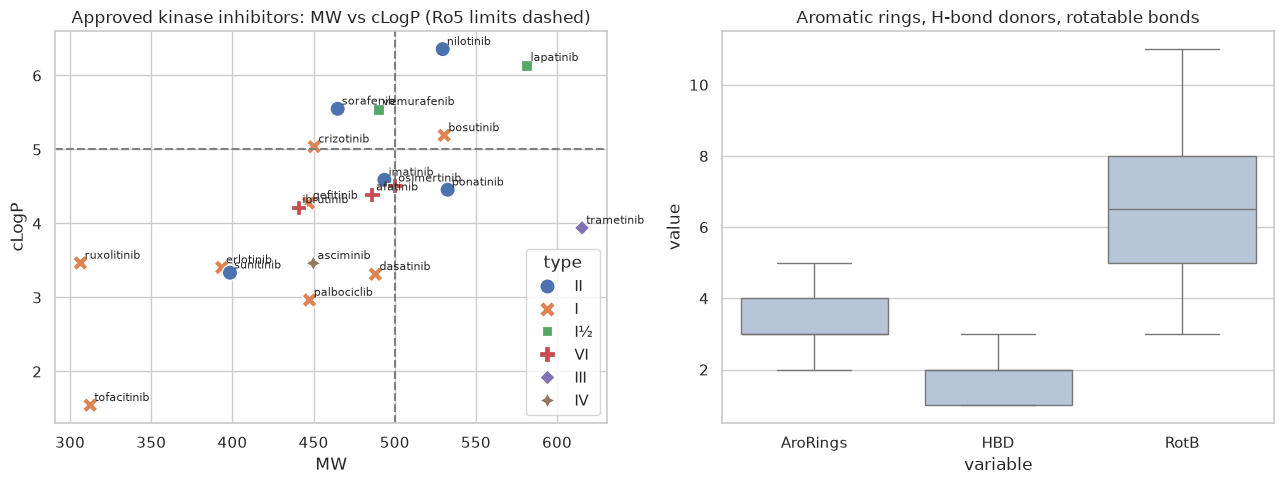

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=props, x="MW", y="cLogP", hue="type", style="type", s=120, ax=axes[0])
axes[0].axvline(500, ls="--", c="grey"); axes[0].axhline(5, ls="--", c="grey")
for _, r in props.iterrows():
    axes[0].annotate(r["name"], (r.MW, r.cLogP), fontsize=8, xytext=(3, 3), textcoords="offset points")
axes[0].set_title("Approved kinase inhibitors: MW vs cLogP (Ro5 limits dashed)")

sns.boxplot(data=props.melt(id_vars="name", value_vars=["AroRings", "HBD", "RotB"]),
            x="variable", y="value", ax=axes[1], color="lightsteelblue")
axes[1].set_title("Aromatic rings, H-bond donors, rotatable bonds")
plt.tight_layout(); plt.show()

**Exercise 1.2** — Which inhibitors violate the Rule of Five? Is there a trend with inhibitor type (hint: type II inhibitors must reach from the hinge into the back pocket)? Is there a trend with approval year?

<details><summary><b>Solution</b></summary>

```python
print(props.loc[props.Ro5_violations > 0, ["name", "type", "MW", "cLogP", "Ro5_violations"]])
print(props.groupby("type")[["MW", "cLogP", "AroRings"]].mean().round(1))
```
Type II inhibitors (imatinib, nilotinib, ponatinib, sorafenib) are on average larger than type I inhibitors: the extra "tail" that occupies the back pocket (usually via an amide/urea that H-bonds to the αC-Glu and the DFG-Asp backbone) adds mass and lipophilicity. Many successful oral kinase drugs sit near or beyond the Ro5 limits.
</details>

### 3.2 Hinge-binding chemotypes and warheads (substructure search)

A few privileged scaffolds dominate kinase medicinal chemistry because they reproduce the adenine–hinge hydrogen bonds. We can find them with **SMARTS** patterns.

In [9]:
motifs = {
    "4-anilinoquinazoline":        "c1ccc2ncnc(Nc3ccccc3)c2c1",
    "2-anilinopyrimidine":         "c1ccnc(Nc2ccccc2)n1",
    "pyrrolo[2,3-d]pyrimidine":    "c1ncnc2[nH]ccc12",
}
motif_hits = pd.DataFrame({name: drugs.mol.apply(lambda m, p=Chem.MolFromSmarts(s): m.HasSubstructMatch(p))
                           for name, s in motifs.items()})
motif_hits.index = drugs.name
motif_hits[motif_hits.any(axis=1)]

,4-anilinoquinazoline,2-anilinopyrimidine,"pyrrolo[2,3-d]pyrimidine"
name,,,
imatinib,False,True,False
gefitinib,True,False,False
erlotinib,True,False,False
nilotinib,False,True,False
lapatinib,True,False,False
ruxolitinib,False,False,True
tofacitinib,False,False,True
afatinib,True,False,False
osimertinib,False,True,False


**Exercise 1.3** — Covalent inhibitors carry an electrophilic **acrylamide** that reacts with a non-catalytic cysteine (EGFR C797, BTK C481).

1. Write a SMARTS pattern for an acrylamide and find all covalent inhibitors in the table.
2. A naive pattern such as `C=CC(=O)N` also hits **sunitinib**. Why? Refine the pattern so that only true acrylamides match.

<details><summary><b>Solution</b></summary>

```python
naive   = Chem.MolFromSmarts("C=CC(=O)N")
refined = Chem.MolFromSmarts("C=!@C-!@C(=O)N")   # '!@' = bond not in a ring
for name, m in zip(drugs.name, drugs.mol):
    if m.HasSubstructMatch(naive) or m.HasSubstructMatch(refined):
        print(f"{name:12s} naive={m.HasSubstructMatch(naive)!s:5}  refined={m.HasSubstructMatch(refined)}")
```
In sunitinib the C=C–C(=O)–N fragment is part of the oxindole (the C–C(=O) bond lies in a ring): it is an α,β-unsaturated lactam that is not designed as a warhead. Requiring acyclic bonds leaves osimertinib, ibrutinib and afatinib.
</details>

In [10]:
# Your answer to Exercise 1.3 here

### 3.3 Chemical similarity

Morgan (ECFP4-like) fingerprints with Tanimoto similarity are the workhorse for comparing molecules; we will reuse them as QSAR descriptors in Notebook 2.

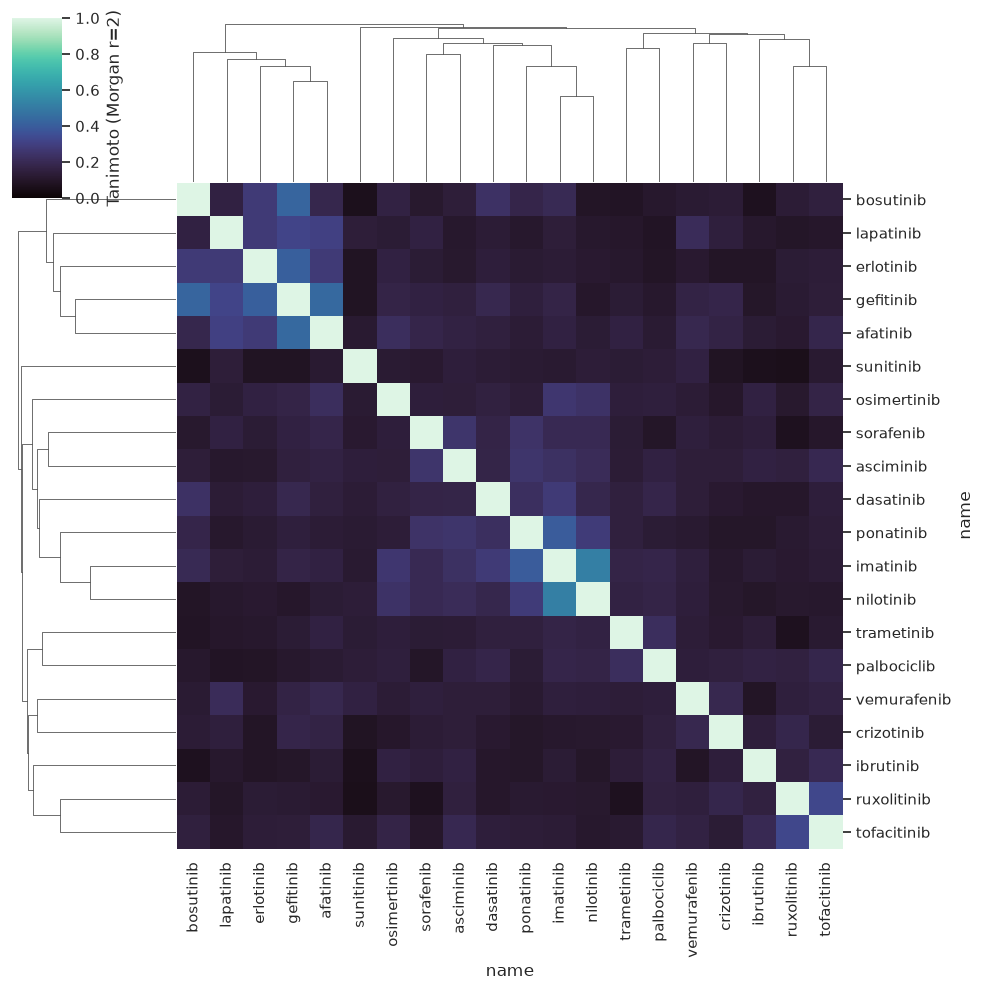

In [11]:
mfpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [mfpgen.GetFingerprint(m) for m in drugs.mol]
sim = pd.DataFrame([DataStructs.BulkTanimotoSimilarity(f, fps) for f in fps],
                   index=drugs.name, columns=drugs.name)
g = sns.clustermap(sim, cmap="mako", vmin=0, vmax=1, figsize=(10, 10),
                   cbar_kws={"label": "Tanimoto (Morgan r=2)"})
plt.show()

The quinazolines (gefitinib, erlotinib, afatinib, lapatinib) and the imatinib/nilotinib pair form clear clusters. Most other pairs have Tanimoto < 0.3: kinase inhibitors with the *same* target can be chemically very different (e.g. imatinib, dasatinib, bosutinib, ponatinib and asciminib all inhibit BCR-ABL).

## 4. Looking at kinase–inhibitor crystal structures

We download four structures from the RCSB PDB:

| PDB | Kinase | Ligand (code) | Expected conformation |
|---|---|---|---|
| 1IEP | ABL (mouse) | imatinib (STI) | type II: **DFG-out**, αC-in |
| 2GQG | ABL | dasatinib (1N1) | type I: DFG-in, αC-in |
| 1M17 | EGFR | erlotinib (AQ4) | type I: DFG-in, αC-in |
| 1XKK | EGFR | lapatinib (FMM) | type I½: DFG-in, **αC-out** |

> **Residue numbering pitfall.** Different structures and papers use different numbering schemes. In 1M17 the EGFR hinge Met is called Met769, while in the modern UniProt numbering it is Met793 (the T790M gatekeeper mutation is "T766M" in older papers). Rather than hard-coding residue numbers, we will **map the KLIFS pocket onto each structure by sequence alignment** and read off the landmarks.

In [17]:
from Bio.PDB import PDBParser
from Bio.SeqUtils import seq1

parser = PDBParser(QUIET=True)
MODIFIED = {"PTR": "Y", "SEP": "S", "TPO": "T", "MSE": "M", "CSO": "C"}

STRUCTURES = {  # pdb_id: (kinase, ligand code, chain)
    "1IEP": ("ABL1", "STI", "A"),
    "2GQG": ("ABL1", "1N1", "A"),
    "1M17": ("EGFR", "AQ4", "A"),
    "1XKK": ("EGFR", "FMM", "A"),
}

def load_chain(pdb_id, chain_id="A"):
    path = download(f"https://files.rcsb.org/download/{pdb_id}.pdb", DATA / f"{pdb_id}.pdb")
    return parser.get_structure(pdb_id, path)[0][chain_id]

def protein_residues(chain):
    """Amino-acid residues (incl. common modified ones) with a CA atom, plus their 1-letter sequence."""
    res = [r for r in chain if "CA" in r and (r.id[0] == " " or r.get_resname() in MODIFIED)]
    seq = "".join(MODIFIED.get(r.get_resname(), seq1(r.get_resname())) for r in res)
    return res, seq

def get_ligand(chain, code):
    het = [r for r in chain if r.id[0].startswith("H_") and r.get_resname() not in MODIFIED]
    hits = [r for r in het if r.get_resname() == code]
    return hits[0] if hits else max(het, key=lambda r: len(r))  # fall back to largest hetero group

def align_pocket(seq, pocket, match=5, mismatch=-4, gap_open=-6, gap_extend=0, missing=-6):
    """Semi-global affine-gap alignment (Gotoh) of a KLIFS pocket (query) to a structure sequence.
    Skipping structure residues between pocket fragments is cheap; leaving a pocket residue
    unmatched (e.g. unresolved in the crystal) costs `missing`. Returns {klifs_pos: seq_index}."""
    q = [(i + 1, aa) for i, aa in enumerate(pocket) if aa != "-"]
    m, n = len(q), len(seq)
    NEG = float("-inf")
    M = [[NEG] * (n + 1) for _ in range(m + 1)]   # pocket residue aligned to structure residue
    X = [[NEG] * (n + 1) for _ in range(m + 1)]   # pocket residue missing in structure
    Y = [[NEG] * (n + 1) for _ in range(m + 1)]   # structure residue skipped (not in pocket)
    for j in range(n + 1):
        M[0][j] = 0.0                              # leading structure residues are free
    for i in range(1, m + 1):
        X[i][0] = missing * i
        for j in range(1, n + 1):
            s = match if q[i - 1][1] == seq[j - 1] else mismatch
            M[i][j] = max(M[i-1][j-1], X[i-1][j-1], Y[i-1][j-1]) + s
            X[i][j] = max(M[i-1][j], X[i-1][j], Y[i-1][j]) + missing
            Y[i][j] = max(M[i][j-1] + gap_open, X[i][j-1] + gap_open, Y[i][j-1] + gap_extend)
    j = max(range(n + 1), key=lambda jj: max(M[m][jj], X[m][jj]))   # trailing residues are free
    i, state = m, ("M" if M[m][j] >= X[m][j] else "X")
    mapping = {}
    while i > 0:
        if state == "M":
            mapping[q[i - 1][0]] = j - 1
            prev = {"M": M[i-1][j-1], "X": X[i-1][j-1], "Y": Y[i-1][j-1]}
            i, j = i - 1, j - 1
        elif state == "X":
            prev = {"M": M[i-1][j], "X": X[i-1][j], "Y": Y[i-1][j]}
            i -= 1
        else:
            prev = {"M": M[i][j-1] + gap_open, "X": X[i][j-1] + gap_open, "Y": Y[i][j-1] + gap_extend}
            j -= 1
        if i == 0:
            break
        state = max(prev, key=prev.get)
    return mapping

def map_klifs_pocket(residues, seq, pocket):
    """Return {KLIFS position (1-85): Biopython residue}."""
    return {pos: residues[idx] for pos, idx in align_pocket(seq, pocket).items()}

In [18]:
def dist(a, b):
    return float(np.linalg.norm(a.coord - b.coord))

def analyse_structure(pdb_id):
    kinase, lig_code, chain_id = STRUCTURES[pdb_id]
    chain = load_chain(pdb_id, chain_id)
    residues, seq = protein_residues(chain)
    pm = map_klifs_pocket(residues, seq, KLIFS_POCKETS[kinase])

    lys, glu, phe = pm.get(17), pm.get(24), pm.get(82)
    # sanity check of the mapping
    for pos, expected in [(17, "LYS"), (24, "GLU"), (81, "ASP"), (82, "PHE")]:
        if pos not in pm or pm[pos].get_resname() != expected:
            print(f"WARNING {pdb_id}: KLIFS position {pos} is not {expected}")
    glu4 = residues[residues.index(glu) + 4]          # αC-Glu(+4), used by Modi & Dunbrack

    D1 = dist(glu4["CA"], phe["CZ"])                   # αC-Glu(+4) CA  – DFG-Phe CZ
    D2 = dist(lys["CA"], phe["CZ"])                    # β3-Lys CA     – DFG-Phe CZ
    KE = min(dist(lys["NZ"], glu[a]) for a in ("OE1", "OE2"))  # salt bridge

    if D1 <= 11 and D2 >= 11:
        dfg = "DFG-in"
    elif D1 > 11 and D2 <= 14:
        dfg = "DFG-out"
    else:
        dfg = "intermediate"
    ac = "αC-in" if KE <= 5.0 else "αC-out"

    lig = get_ligand(chain, lig_code)
    lig_xyz = np.array([a.coord for a in lig if a.element != "H"])
    contacts = []
    for pos, r in pm.items():
        d = np.min(np.linalg.norm(np.array([a.coord for a in r])[:, None, :] - lig_xyz[None], axis=-1))
        if d <= 4.0:
            contacts.append(pos)
    return {
        "pdb": pdb_id, "kinase": kinase, "ligand": lig.get_resname(),
        "β3-Lys": f"K{lys.id[1]}", "αC-Glu": f"E{glu.id[1]}", "gatekeeper": f"{seq1(pm[45].get_resname())}{pm[45].id[1]}",
        "hinge": "-".join(f"{seq1(pm[p].get_resname())}{pm[p].id[1]}" for p in (46, 47, 48) if p in pm),
        "DFG": f"D{pm[81].id[1]}-F{phe.id[1]}-G{pm[83].id[1]}" if 83 in pm else f"D{pm[81].id[1]}-F{phe.id[1]}",
        "D1 (Å)": round(D1, 1), "D2 (Å)": round(D2, 1), "K–E (Å)": round(KE, 1),
        "DFG state": dfg, "αC state": ac,
        "n pocket contacts": len(contacts),
        "regions contacted": sorted({klifs_region(p) for p in contacts}, key=lambda x: [r[0] for r in KLIFS_REGIONS].index(x)),
        "_contacts": contacts, "_pm": pm,
    }

results = {pid: analyse_structure(pid) for pid in STRUCTURES}
summary = pd.DataFrame(results.values()).drop(columns=["_contacts", "_pm"]).set_index("pdb")
summary

,kinase,ligand,β3-Lys,αC-Glu,gatekeeper,hinge,DFG,D1 (Å),D2 (Å),K–E (Å),DFG state,αC state,n pocket contacts,regions contacted
pdb,,,,,,,,,,,,,,
1IEP,ABL1,STI,K271,E286,T315,E316-F317-M318,D381-F382-G383,13.6,10.9,3.1,DFG-out,αC-in,21,"[I, g.l, II, III, αC, b.l, V, GK, hinge, linke..."
2GQG,ABL1,1N1,K271,E286,T315,E316-F317-M318,D381-F382-G383,6.6,14.0,3.3,DFG-in,αC-in,18,"[I, g.l, III, αC, b.l, V, GK, hinge, linker, V..."
1M17,EGFR,AQ4,K721,E738,T766,Q767-L768-M769,D831-F832-G833,6.0,14.8,3.1,DFG-in,αC-in,15,"[I, III, αC, V, GK, hinge, linker, VII, xDFG]"
1XKK,EGFR,FMM,K745,E762,T790,Q791-L792-M793,D855-F856-G857,4.6,13.9,13.5,DFG-in,αC-out,23,"[I, II, III, αC, b.l, IV, V, GK, hinge, linker..."


**What to look for**

* Landmark residue numbers can differ between structures of the same kinase (e.g. ABL isoform 1a vs 1b numbering, old vs UniProt EGFR numbering) — the KLIFS mapping makes this irrelevant.
* **1IEP** (imatinib) is classified **DFG-out** — the Phe has flipped into the ATP site so that imatinib can occupy the back pocket. Dasatinib (**2GQG**) binds DFG-in.
* **1XKK** (lapatinib) has a broken Lys–Glu salt bridge: **αC-out**. Lapatinib's large 3-fluorobenzyloxy group sits in the pocket created by the outward-moved helix (type I½).
* The DFG thresholds used here are a simplified version of the scheme of Modi & Dunbrack (PNAS 2019): D1 = dist(αC-Glu+4 Cα, DFG-Phe Cζ), D2 = dist(β3-Lys Cα, DFG-Phe Cζ).

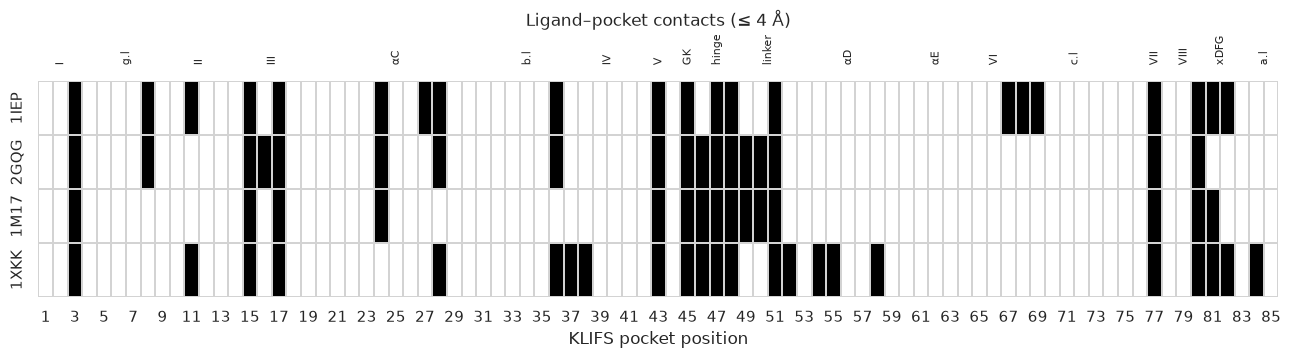

In [19]:
# Which KLIFS regions does each ligand touch? (1 = residue within 4 Å of the ligand)
contact_matrix = pd.DataFrame(0, index=list(results), columns=range(1, 86))
for pid, r in results.items():
    contact_matrix.loc[pid, r["_contacts"]] = 1

fig, ax = plt.subplots(figsize=(16, 2.8))
sns.heatmap(contact_matrix, cmap="Greys", cbar=False, linewidths=0.2, linecolor="lightgrey", ax=ax)
for name, s, e in KLIFS_REGIONS:  # region labels on top
    ax.text((s + e) / 2 - 0.5, -0.3, name, ha="center", va="bottom", fontsize=8, rotation=90)
ax.set_xlabel("KLIFS pocket position"); ax.set_title("Ligand–pocket contacts (≤ 4 Å)", pad=40)
plt.show()

**Exercise 1.4** — Compare the contact fingerprints. Which positions are contacted by the type II inhibitor imatinib but *not* by the type I inhibitors? Which KLIFS regions are they in? Which positions are contacted by all four ligands?

<details><summary><b>Solution</b></summary>

```python
only_imatinib = [p for p in range(1, 86) if contact_matrix.loc["1IEP", p] == 1
                 and contact_matrix.loc[["2GQG", "1M17"], p].sum() == 0]
print("imatinib only:", [(p, klifs_region(p)) for p in only_imatinib])
all_four = [p for p in range(1, 86) if contact_matrix[p].sum() == 4]
print("all four:", [(p, klifs_region(p)) for p in all_four])
```
Imatinib reaches into the back pocket: αC-helix, back loop (b.l), β4/β5 and the flipped xDFG region. All ligands contact the "core" ATP site: hinge, gatekeeper, β1/β3 (incl. the catalytic Lys), the glycine-rich loop and the catalytic loop area.
</details>

In [20]:
# Your answer to Exercise 1.4 here

### 4.1 Interactive 3D view

The cell below shows ABL–imatinib (1IEP, chain A). Colours: **hinge** orange, **gatekeeper** red, **β3-Lys / αC-Glu** blue, **DFG** magenta, **αC-helix** cartoon in light blue, glycine-rich loop in green. Rotate with the mouse, zoom with the scroll wheel.

In [21]:
def show_complex(pdb_id, width=850, height=520):
    r = results[pdb_id]
    pm = r["_pm"]
    rid = lambda p: int(pm[p].id[1])
    chain = STRUCTURES[pdb_id][2]
    view = py3Dmol.view(width=width, height=height)
    view.addModel((DATA / f"{pdb_id}.pdb").read_text(), "pdb")
    view.setStyle({}, {})                                            # hide everything
    view.setStyle({"chain": chain}, {"cartoon": {"color": "lightgrey", "opacity": 0.85}})
    view.setStyle({"chain": chain, "resi": [rid(p) for p in range(20, 31) if p in pm]},
                  {"cartoon": {"color": "lightblue"}})              # αC helix
    view.setStyle({"chain": chain, "resi": [rid(p) for p in range(4, 10) if p in pm]},
                  {"cartoon": {"color": "palegreen"}})              # glycine-rich loop
    groups = {"orange": [46, 47, 48], "red": [45], "blue": [17, 24], "magenta": [81, 82, 83]}
    for colour, positions in groups.items():
        sel = {"chain": chain, "resi": [rid(p) for p in positions if p in pm]}
        view.addStyle(sel, {"stick": {"color": colour, "radius": 0.2}})
    view.addStyle({"chain": chain, "resn": r["ligand"]}, {"stick": {"colorscheme": "greenCarbon", "radius": 0.25}})
    view.zoomTo({"chain": chain, "resn": r["ligand"]})
    return view

show_complex("1IEP").show()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

**Exercise 1.5** — Display the dasatinib complex (`show_complex("2GQG")`) and the lapatinib complex (`"1XKK"`). Compare the position of the DFG-Phe (magenta) and of the αC-helix with the imatinib complex. Can you see the hinge H-bond from the aminothiazole of dasatinib to Met318?

In [ ]:
# Your answer to Exercise 1.5 here

## 5. Resistance and selectivity — why modelling helps

Clinically important resistance mutations cluster in the ATP pocket:

| Kinase | Mutation (UniProt numbering) | KLIFS position / region | Effect | Answer from medicinal chemistry |
|---|---|---|---|---|
| ABL1 | **T315I** | 45 / gatekeeper | removes the Thr OH H-bond and blocks the back pocket for imatinib, nilotinib, dasatinib | ponatinib (alkyne linker), asciminib (allosteric) |
| EGFR | **T790M** | 45 / gatekeeper | restores ATP affinity, reduces 1st-gen inhibitor potency | osimertinib (covalent, C797) |
| EGFR | **C797S** | hinge-adjacent (solvent front) | removes the covalent anchor | 4th-generation / allosteric inhibitors (research) |
| BTK | **C481S** | hinge-adjacent | removes the covalent anchor of ibrutinib | non-covalent BTK inhibitors (e.g. pirtobrutinib) |

Two computational strategies follow naturally from this notebook:

* **Ligand-based (Notebook 2):** learn structure–activity relationships from tens of thousands of measured kinase–compound affinities in ChEMBL. With **proteochemometrics (PCM)** we add a description of the *protein* (e.g. the 85 KLIFS pocket residues) so a single model can predict affinities for many kinases — including selectivity profiles and, in principle, mutants.
* **Structure-based (Notebook 3):** dock inhibitors into a crystal structure, compare wild type with an in-silico T315I mutant, and use molecular dynamics to look at the stability of the hinge H-bonds and the DFG/αC conformation over time.

### Key resources

* **ChEMBL** — manually curated bioactivities (https://www.ebi.ac.uk/chembl/)
* **Papyrus** — standardised, aggregated bioactivity set built from ChEMBL, ExCAPE-DB and others, ready for modelling (Béquignon *et al.*, J Cheminform 2023)
* **KLIFS** — kinase–ligand interaction fingerprints and the 85-residue pocket (https://klifs.net)
* **RCSB PDB** — experimental structures (https://www.rcsb.org)
* **KinCore** — kinase conformational classification (Modi & Dunbrack)

### Check your understanding

1. Why does a large gatekeeper residue confer resistance to type II inhibitors in particular?
2. Lapatinib is classified as type I½. What does that tell you about the conformation of EGFR in 1XKK?
3. Two kinases share 80% pocket identity. Give one reason why an inhibitor could still be selective between them.
4. Why are acrylamide warheads compatible with oral drugs despite being electrophiles?